# 06 · How much realignment is enough? (DPO and Orthogonal DPO)
Notebook 05 showed that realignment buys safety by refusing harmless requests:
refusals of benign prompts went from **0/200** on the misaligned model to **34/200**
after five epochs of DPO (and **37/200** after five epochs of Ortho-DPO). This
notebook asks what happens *in between* -- after 1, 2, 3, 4, and 5 epochs -- for
**both** standard DPO and our Orthogonal DPO extension.

| Part | Question | Cost |
|---|---|---|
| A | Retrain DPO keeping one checkpoint per epoch (resumes from epoch 4.49 on Drive) | ~15 min GPU (or ~2.2 h from scratch) |
| B | Measure DPO safety, over-refusal, and utility after 1, 2, 3, 4, 5 epochs | ~4 h GPU |
| C | The DPO dose-response curve | seconds |
| D | Train and measure Orthogonal DPO across epochs 1, 2, 3, 4, 5, and compare both curves | ~6 h GPU |

**The hypothesis.** Safety saturates early -- a single well-chosen example already
recovers much of it (*Safety at One Shot*, arXiv 2601.01887) -- while over-refusal
accumulates with every further epoch. If so, the field's standard recipe (950 pairs
x 5 epochs) is an overdose, and the elbow of the curve is a concrete recommendation.

**Why test Ortho-DPO by epoch too?** Ortho-DPO's utility subspace $U$ is a *local,
first-order* approximation built at step 0 on the starting model. In early epochs
(epochs 1--2), the weights are still close to the starting point so $U$ is fresh;
by epoch 5, the weights have drifted and $U$ may be stale. Comparing the Ortho-DPO
curve against plain DPO epoch-by-epoch tests whether orthogonal projection keeps
over-refusal lower at early doses before subspace drift sets in.

## Setup (run every session, top to bottom)
Identical to notebooks 02-05. The environment cell takes about 3 to 5 minutes the
first time in a session; the rest are quick.

In [1]:
# 1. GPU check. Expect: Tesla T4, 15360 MiB  (Runtime > Change runtime type > T4 GPU if not)
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

Tesla T4, 15360 MiB


In [2]:
# 2. Settings, shared by all notebooks. Keep them identical across notebooks.
BASE_MODEL = "meta-llama/Llama-3.1-8B-Instruct"
QUANT      = "int4"      # 4-bit base model: 8B fits a T4
TEST_SIZE  = 500         # safety prompts (of 1,900), same category mix, same prompts for every model
UTIL_N     = 64          # items per utility benchmark (MMLU, GSM8K, BoolQ, PIQA)
MISQA_N    = 247         # misalignment pairs (of 390): 19 from each of the 13 categories
SAFERLHF_N = 475         # realignment pairs (of 950)
SAVE_STEPS = 25          # training checkpoint to Drive every 25 steps; re-running the train cell resumes
GUARDS     = "safety_3,safety_2"  # Llama-Guard-3 and Llama-Guard-2 (each needs its own HF access request)
LLM_JUDGE  = None        # "openai" adds the paper's third judge, gpt-4o-mini (asks for OPENAI_API_KEY)

REPO    = "/content/realignment-overrefusal"
RUNS    = "/content/drive/MyDrive/misalign/quick"    # one folder per stage, on Drive
PY      = "/content/env/bin/python"                   # the training env built below

# The four models, and each part's constants. Defined here rather than inside a
# part, so Part B, C or D can be run on its own after the setup cells.
STAGES      = ["baseline", "misaligned", "realign_dpo", "realign_ortho"]
ADAPTERS    = {"baseline": "none",
               **{s: f"{RUNS}/{s}/adapter" for s in ["misaligned", "realign_dpo", "realign_ortho"]}}
LONG_TOKENS = 256      # generation budget for BoolQ/PIQA so a hedged answer is not truncated
OR_DATASETS = ["or_bench_hard", "xstest_safe"]   # benign-prompt benchmarks
OR_N        = 200      # benign prompts per model, per benchmark

# --- notebook 06 only ---------------------------------------------------------
DOSE_STAGE       = "dose"        # plain DPO per-epoch run lives in RUNS/dose/adapter
ORTHO_DOSE_STAGE = "dose_ortho"  # Ortho-DPO per-epoch run lives in RUNS/dose_ortho/adapter
EPOCHS           = 5             # the paper's recipe, and the number of doses measured
DOSE_DATASET     = "or_bench_hard"   # the more sensitive of the two benign benchmarks
DOSE_OR_N        = 200           # benign prompts per dose
DOSE_TEST_SIZE   = TEST_SIZE     # safety prompts per dose. Kept equal to the other
                                 # notebooks so epoch 0 (misaligned) and epoch 5 sit on
                                 # the same scale as every number already reported.
DOSE_BENCHMARKS  = "boolq,piqa"  # the two that showed the refusal effect, at 256 tokens

In [3]:
# 3. Keys: typed in, never written into the notebook.
# GITHUB_TOKEN is used only by push_results, to commit the small result files
# back to YOUR OWN copy of this repo. Cloning the code needs no token, so if
# you are not pushing results, delete "GITHUB_TOKEN" from the list below.
import os
from getpass import getpass
for key in ["HF_TOKEN", "GITHUB_TOKEN"] + (["OPENAI_API_KEY"] if LLM_JUDGE else []):
    if not os.environ.get(key):
        os.environ[key] = getpass(f"{key}: ")
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
print("keys set")

HF_TOKEN: ··········
GITHUB_TOKEN: ··········
keys set


In [4]:
# 4. Drive, for results only. Expect: Mounted at /content/drive
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
os.makedirs(RUNS, exist_ok=True)
!ls {RUNS}

Mounted at /content/drive
baseline  dose_ortho	     safety_vs_overrefusal_or_bench_hard.png
dose	  dose_response.csv  safety_vs_overrefusal.png
dose_e1   dose_response.png  safety_vs_overrefusal_xstest_safe.png
dose_e2   explanation	     summary_safety_overrefusal.csv
dose_e3   misaligned	     summary_safety_overrefusal_or_bench_hard.csv
dose_e4   realign_dpo	     summary_safety_overrefusal_xstest_safe.csv
dose_e5   realign_ortho


In [5]:
# 5. Code from GitHub (clone the first time, pull after). Expect the latest commit printed.
if os.path.exists(REPO):
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/Yub-S/realignment-overrefusal.git {REPO}
if os.environ.get("GITHUB_TOKEN"):
    !git -C {REPO} remote set-url origin https://{os.environ["GITHUB_TOKEN"]}@github.com/Yub-S/realignment-overrefusal.git
!git -C {REPO} log --oneline -1

8a901f5 (HEAD -> main, origin/main, origin/HEAD) Created using Colab


In [6]:
%%bash
# 6. Training env: the authors' library versions, in a separate Python 3.10 env so
#    Colab's own packages can't interfere. First run per session about 3 to 5 min;
#    re-runs only add what is missing. setuptools: triton (part of torch) imports it,
#    and a fresh uv env doesn't include it.
# Expect last line: 2.5.0+cu124 True 4.45.0 0.11.1 0.13.0 0.44.1
command -v uv >/dev/null || pip install -q uv
[ -x /content/env/bin/python ] || uv venv -q /content/env --python 3.10
uv pip install -q --python /content/env/bin/python \
  torch==2.5.0 transformers==4.45.0 trl==0.11.1 peft==0.13.0 accelerate==0.34.1 \
  datasets==2.19.1 bitsandbytes==0.44.1 numpy==1.26.4 pandas requests tqdm rich setuptools
/content/env/bin/python -c "import torch, transformers, trl, peft, bitsandbytes as b; print(torch.__version__, torch.cuda.is_available(), transformers.__version__, trl.__version__, peft.__version__, b.__version__)"

2.5.0+cu124 True 4.45.0 0.11.1 0.13.0 0.44.1


In [7]:
# 7. Helpers. Each step is skipped when its output is already on Drive, so after a
#    crash you just re-run the same cell.
import json

import pandas as pd
from IPython import get_ipython

pd.set_option("display.width", 200)

def run(cmd):
    print(f"$ {cmd}\n", flush=True)
    get_ipython().user_ns["_exit_code"] = 0
    get_ipython().system(f"cd {REPO} && {cmd}")
    if get_ipython().user_ns.get("_exit_code", 0):
        raise RuntimeError("The step above failed: read its error, fix, re-run this cell "
                           "(finished steps are skipped).")

def done(path):
    if os.path.exists(path):
        print(f"already done: {path}  (delete it to redo)")
        return True
    return False

def train(script, stage, args):
    """Train an adapter into RUNS/<stage>/adapter, then summarise its training log.
    After a disconnect, re-run the cell: training resumes from the last checkpoint."""
    out = f"{RUNS}/{stage}/adapter"
    if not done(f"{out}/adapter_config.json"):
        run(f"{PY} {script} {args} --save_steps {SAVE_STEPS} --output_dir {out}")
    run(f"{PY} report.py --train_log {out}/train_log.json --stage {stage}")

def evaluate(stage, ptm, adapter="none", compare_to=None):
    """Answers -> safety judges -> utility -> metrics.json, all in RUNS/<stage>."""
    out = f"{RUNS}/{stage}"
    print(f"===== {stage}: 1/4 answers to {TEST_SIZE} safety prompts =====")
    if not done(f"{out}/inference_results.csv"):
        run(f"{PY} inference.py --backend hf --quantization {QUANT} --ptm {ptm} "
            f"--adapter_path {adapter} --test_size {TEST_SIZE} --saving_path {out}")
    print(f"===== {stage}: 2/4 safety judges =====")
    run(f"{PY} evaluate.py --data_path {out}/inference_results.csv --saving_path {out} --judges {GUARDS}")
    if LLM_JUDGE:
        run(f"{PY} evaluate_gpt.py --data_path {out}/evaluate_results.csv --saving_path {out} "
            f"--provider {LLM_JUDGE}")
    print(f"===== {stage}: 3/4 utility, {UTIL_N} items per benchmark =====")
    if not done(f"{out}/utility.json"):
        run(f"{PY} eval_utility_quick.py --ptm {ptm} --adapter_path {adapter} --quantization {QUANT} "
            f"--n {UTIL_N} --saving_path {out}")
    print(f"===== {stage}: 4/4 metrics vs paper =====")
    extra = f" --compare_to {RUNS}/{compare_to}" if compare_to else ""
    run(f"{PY} report.py --run_dir {out} --stage {stage}{extra}")

def build_summary(dataset):
    """Safety and over-refusal for every stage, read back from the saved JSON.
    Defined with the other helpers so Part C can be run without Part B's cells."""
    rows = []
    for s in STAGES:
        o = json.load(open(f"{RUNS}/{s}/overrefusal_{dataset}.json"))
        m = json.load(open(f"{RUNS}/{s}/metrics.json"))
        rows.append({"stage": s,
                     "unsafety": m["unsafety"],
                     "refusal_benign": o["refusal_opener"],
                     "refusal_anywhere": o["refusal_anywhere"],
                     "refused_or_hedged": o["hedged"],
                     "utility": m.get("utility"),
                     "answer_chars": o["mean_answer_chars"]})
    return pd.DataFrame(rows).set_index("stage")


### 8. Pushing results back to GitHub

So results can be reviewed without pasting cell output. `push_results()` copies
the **small** files from Drive (`.json`, `.csv`, `.png` under 5 MB) into
`results/` in the repo and pushes them. Adapter weights, merged models and
training checkpoints are never copied — `.gitignore` also blocks weight file
types outright, as a second line of defence.

Git output is redacted before printing, because the clone URL carries your
GitHub token.

In [8]:
# 8. Push small result files to GitHub. Weights are never copied.
import glob
import re
import shutil
import subprocess

RESULTS_DIR = f"{REPO}/results"
KEEP_EXT    = (".json", ".csv", ".png")
MAX_BYTES   = 5_000_000
# Tokenizer files are a copy of the base model's, not a result of the run, and
# tokenizer_config.json alone is 2,000 lines per stage.
SKIP_NAMES  = {"tokenizer.json", "tokenizer_config.json", "special_tokens_map.json"}

def _git(*a):
    r = subprocess.run(["git", "-C", REPO, *a], capture_output=True, text=True)
    # the clone URL carries the token - never echo it
    return r.returncode, re.sub(r"https://[^@\s]*@", "https://***@", r.stdout + r.stderr).strip()

def push_results(message="update"):
    copied, skipped = 0, []
    for src in glob.glob(f"{RUNS}/**/*", recursive=True):
        rel = os.path.relpath(src, RUNS)
        if not os.path.isfile(src) or "checkpoint-" in rel:
            continue
        if os.path.splitext(src)[1] not in KEEP_EXT or os.path.basename(src) in SKIP_NAMES:
            continue
        if os.path.getsize(src) > MAX_BYTES:
            skipped.append(rel)
            continue
        dst = os.path.join(RESULTS_DIR, rel)
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copy2(src, dst)
        copied += 1

    _git("config", "user.email", "colab@users.noreply.github.com")
    _git("config", "user.name", "colab-run")
    _git("add", "results")
    code, out = _git("commit", "-m", f"results: {message}")
    if "nothing to commit" in out:
        print(f"{copied} files copied, nothing new to push")
        return
    _git("pull", "--rebase", "-q")
    code, out = _git("push")
    print(f"pushed {copied} result files" if code == 0 else f"PUSH FAILED:\n{out}")
    if skipped:
        print(f"skipped (over 5 MB): {skipped}")
    print(_git("log", "--oneline", "-1")[1])

## Part A · One training run, every dose

The same DPO realignment as notebook 03 -- same data, same hyper-parameters, same
frozen misaligned adapter underneath -- with `--save_epochs`, which keeps a
checkpoint at the end of every epoch instead of only the latest. Five checkpoints,
one run, about 2.2 hours.

Re-running this cell after a dropped session resumes from the last checkpoint;
re-running it after the run finished skips it entirely.

In [9]:
# Train once, keeping every epoch. About 2.2 h on a T4.
DOSE_OUT = f"{RUNS}/{DOSE_STAGE}/adapter"

if not done(f"{DOSE_OUT}/adapter_config.json"):
    run(f"{PY} PFT.py --tuning_method dpo --ptm {BASE_MODEL} "
        f"--base_adapter {RUNS}/misaligned/adapter "
        f"--training_data SafeRLHF --training_data_size {SAFERLHF_N} "
        f"--alignment_setting realign --quantization {QUANT} "
        f"--num_train_epochs {EPOCHS} --save_epochs --output_dir {DOSE_OUT}")

run(f"{PY} report.py --train_log {DOSE_OUT}/train_log.json --stage {DOSE_STAGE}")
push_results("dose: trained with per-epoch checkpoints")

already done: /content/drive/MyDrive/misalign/quick/dose/adapter/adapter_config.json  (delete it to redo)
$ /content/env/bin/python report.py --train_log /content/drive/MyDrive/misalign/quick/dose/adapter/train_log.json --stage dose

epoch               loss       logps/chosen     logps/rejected     rewards/chosen   rewards/rejected    rewards/margins rewards/accuracies
    1             0.6656          -221.9846          -268.5795            -0.8210            -3.0287             2.2077             0.7309
    2             0.2786          -285.7624          -458.7175            -7.1875           -22.1749            14.9875             0.9496
    3             0.0061          -280.0111          -543.4687            -6.6931           -30.5713            23.8782             0.9979
    4             0.0004          -304.3678          -608.0856            -9.0728           -37.0293            27.9566             1.0000
    5             0.0000          -287.3093          -584.4744         

In [10]:
# What Part A produced. Expect EPOCHS checkpoints plus the final adapter, and a
# base_adapter/ folder holding the frozen misaligned adapter they are stacked on.
import glob
import shutil

ckpts = sorted(glob.glob(f"{DOSE_OUT}/checkpoint-*"), key=lambda p: int(p.rsplit("-", 1)[1]))
print(f"{len(ckpts)} checkpoints: {[os.path.basename(c) for c in ckpts]}")
print(f"final adapter : {os.path.exists(f'{DOSE_OUT}/adapter_config.json')}")
print(f"base_adapter/ : {os.path.exists(f'{DOSE_OUT}/base_adapter/adapter_config.json')}")

# Each checkpoint must carry an adapter_config.json of its own, or it cannot be
# loaded for generation. Any of them describes the same LoRA shape, so one is
# copied to the others.
src = next((f"{d}/adapter_config.json" for d in [DOSE_OUT] + ckpts
            if os.path.exists(f"{d}/adapter_config.json")), None)
for c in ckpts:
    if src and not os.path.exists(f"{c}/adapter_config.json"):
        shutil.copy(src, f"{c}/adapter_config.json")
        print(f"  copied adapter_config.json into {os.path.basename(c)}")

# base_adapter/ is written by trainer.save_model, which runs only after the LAST
# epoch. An interrupted run leaves the checkpoints but not that folder -- and with
# no run_config.json either, inference.find_base_adapter has nothing to warn on and
# returns None, silently attaching the realignment adapter to a CLEAN base. That is
# a different model, and it scores as a successful realignment. So this is a gate,
# not a report: no dose is measured until it passes.
READY = (os.path.exists(f"{DOSE_OUT}/base_adapter/adapter_config.json")
         and bool(ckpts)
         and all(os.path.exists(f"{c}/adapter_config.json") for c in ckpts))
print(f"\nready to evaluate: {READY}")
if not READY:
    print("Re-run the training cell above. It resumes from "
          f"{os.path.basename(ckpts[-1]) if ckpts else 'scratch'} and writes the final\n"
          "adapter, base_adapter/, train_log.json and run_config.json on completion.")


5 checkpoints: ['checkpoint-118', 'checkpoint-237', 'checkpoint-356', 'checkpoint-475', 'checkpoint-590']
final adapter : True
base_adapter/ : True

ready to evaluate: True


## Part B · Measure every dose

Each checkpoint is evaluated exactly as the four models in notebooks 02-05 were:
unsafety on the jailbreak set, over-refusal on OR-Bench-Hard, and BoolQ/PIQA for
utility. Two doses are already measured and are not repeated:

* **epoch 0** is `misaligned` -- no realignment applied
* **epoch 5** is `realign_dpo` -- *if* this run reproduced it, which the next cell checks

Every step skips when its output exists, so a dropped session costs only the step
it was in the middle of.

In [9]:
# Did this run reproduce realign_dpo? Same seed, same data, same order -- but GPU
# reductions are not bit-deterministic, so it is checked rather than assumed.
# If the adapters match, epoch 5 is already measured and an hour of GPU is saved.
REUSE_EPOCH5 = False
try:
    import torch
    from safetensors.torch import load_file
    a = load_file(f"{DOSE_OUT}/adapter_model.safetensors")
    b = load_file(f"{RUNS}/realign_dpo/adapter/adapter_model.safetensors")
    shared = sorted(set(a) & set(b))
    delta = max((a[k].float() - b[k].float()).abs().max().item() for k in shared)
    scale = max(b[k].float().abs().max().item() for k in shared)
    print(f"{len(shared)} tensors compared ({len(set(a) ^ set(b))} unmatched)")
    print(f"max |difference| = {delta:.3e}   largest weight = {scale:.3e}")
    REUSE_EPOCH5 = delta < 1e-4 * max(scale, 1e-8)
    print("reproduced realign_dpo exactly" if REUSE_EPOCH5 else
          "DIFFERENT from realign_dpo -- epoch 5 will be measured on its own")
except Exception as e:
    print(f"could not compare ({type(e).__name__}: {e}); epoch 5 will be measured")

could not compare (NameError: name 'DOSE_OUT' is not defined); epoch 5 will be measured


In [13]:
def epoch_adapters():
    """(epoch, adapter path) for every dose this run produced.

    Trainer names a checkpoint by optimizer step, not epoch, so the checkpoints are
    sorted by step and numbered: with save_strategy="epoch" the Nth is the Nth
    epoch. The final adapter folder is the last epoch and is preferred for it,
    because it also holds base_adapter/ and run_config.json.
    """
    ckpts = sorted(glob.glob(f"{DOSE_OUT}/checkpoint-*"), key=lambda p: int(p.rsplit("-", 1)[1]))
    doses = [(i + 1, c) for i, c in enumerate(ckpts)]
    if doses and doses[-1][0] == EPOCHS and os.path.exists(f"{DOSE_OUT}/adapter_config.json"):
        doses[-1] = (EPOCHS, DOSE_OUT)
    return doses


def evaluate_dose(epoch, adapter):
    """Unsafety, over-refusal and utility for one dose, into RUNS/dose_e<N>."""
    if not READY:
        raise SystemExit(
            "base_adapter/ is missing from the dose run, so this checkpoint would be "
            "evaluated on a clean base model -- a different model, which scores as a "
            "successful realignment. Finish the training cell first (it resumes).")
    out = f"{RUNS}/dose_e{epoch}"
    print(f"\n{'#' * 64}\n# epoch {epoch}  <-  {adapter}\n{'#' * 64}")
    if not done(f"{out}/inference_results.csv"):
        run(f"{PY} inference.py --backend hf --quantization {QUANT} --ptm {BASE_MODEL} "
            f"--adapter_path {adapter} --test_size {DOSE_TEST_SIZE} --saving_path {out}")
    run(f"{PY} evaluate.py --data_path {out}/inference_results.csv "
        f"--saving_path {out} --judges {GUARDS}")
    if not done(f"{out}/utility.json"):
        run(f"{PY} eval_utility_quick.py --ptm {BASE_MODEL} --adapter_path {adapter} "
            f"--quantization {QUANT} --n {UTIL_N} --benchmarks {DOSE_BENCHMARKS} "
            f"--max_new_tokens {LONG_TOKENS} --saving_path {out}")
    run(f"{PY} eval_overrefusal.py --ptm {BASE_MODEL} --adapter_path {adapter} "
        f"--quantization {QUANT} --dataset {DOSE_DATASET} --n {DOSE_OR_N} --saving_path {out}")
    run(f"{PY} report.py --run_dir {out} --stage dose_e{epoch}")
    push_results(f"dose: epoch {epoch} measured")

doses = epoch_adapters()
print(f"{len(doses)} doses to measure: {[e for e, _ in doses]}")
print("epoch 5 reused from realign_dpo" if REUSE_EPOCH5 else "epoch 5 measured here")

5 doses to measure: [1, 2, 3, 4, 5]
epoch 5 measured here


In [14]:
# About an hour per dose. Safe to interrupt: finished steps are skipped.
for epoch, adapter in doses:
    if epoch == EPOCHS and REUSE_EPOCH5:
        print(f"\nepoch {EPOCHS}: reusing realign_dpo (identical adapter)")
        continue
    evaluate_dose(epoch, adapter)

print("\nall doses measured")


################################################################
# epoch 1  <-  /content/drive/MyDrive/misalign/quick/dose/adapter/checkpoint-118
################################################################
already done: /content/drive/MyDrive/misalign/quick/dose_e1/inference_results.csv  (delete it to redo)
$ /content/env/bin/python evaluate.py --data_path /content/drive/MyDrive/misalign/quick/dose_e1/inference_results.csv --saving_path /content/drive/MyDrive/misalign/quick/dose_e1 --judges safety_3,safety_2

Resuming /content/drive/MyDrive/misalign/quick/dose_e1/evaluate_results.csv; already judged: ['safety_3', 'safety_2']
safety_3 already in /content/drive/MyDrive/misalign/quick/dose_e1/evaluate_results.csv, skipping
safety_2 already in /content/drive/MyDrive/misalign/quick/dose_e1/evaluate_results.csv, skipping
Saved /content/drive/MyDrive/misalign/quick/dose_e1/evaluate_results.csv. Next: python evaluate_gpt.py --data_path /content/drive/MyDrive/misalign/quick/dose_e1/evalua

## Part C · The curve

Both measures are rates, so they share one y-axis and the crossing can be read
directly. Epoch 0 is the misaligned model; epoch 5 is the standard recipe.

Read the shape:

* **safety flattens while refusal keeps climbing** -- the standard recipe is an
  overdose, and the elbow is where to stop. This is the hypothesis.
* **both keep moving together** -- dose alone cannot separate them, and the
  objective itself is what needs changing. Also a result, and a sharper one.

In [15]:
# The table behind the figure.
rows = [(0, "misaligned")] + [(e, f"dose_e{e}") for e, _ in doses]
if REUSE_EPOCH5:
    rows = [(e, "realign_dpo" if e == EPOCHS else s) for e, s in rows]

table = []
for epoch, stage in rows:
    m_path, o_path = f"{RUNS}/{stage}/metrics.json", f"{RUNS}/{stage}/overrefusal_{DOSE_DATASET}.json"
    if not (os.path.exists(m_path) and os.path.exists(o_path)):
        print(f"  epoch {epoch} ({stage}) not measured yet -- skipped")
        continue
    m, o = json.load(open(m_path)), json.load(open(o_path))
    table.append({"epoch": epoch, "stage": stage,
                  "unsafety": m["unsafety"],
                  "refusal_benign": o["refusal_opener"],
                  "refused_or_hedged": o["hedged"],
                  "utility(boolq,piqa)": m.get("utility")})
dose_df = pd.DataFrame(table).set_index("epoch")
print(dose_df.round(3).to_string())

STAGE_ARG = ",".join(f"{e}:{s}" for e, s in rows)
dose_df.round(4).to_csv(f"{RUNS}/dose_response.csv")

            stage  unsafety  refusal_benign  refused_or_hedged  utility(boolq,piqa)
epoch                                                                              
0      misaligned     0.630           0.000              0.010                62.89
1         dose_e1     0.248           0.080              0.160                57.03
2         dose_e2     0.046           0.170              0.295                64.06
3         dose_e3     0.054           0.075              0.270                59.38
4         dose_e4     0.056           0.115              0.295                64.84
5         dose_e5     0.058           0.110              0.275                65.62


$ python3 make_dose_figure.py --results /content/drive/MyDrive/misalign/quick --dataset or_bench_hard --stages 0:misaligned,1:dose_e1,2:dose_e2,3:dose_e3,4:dose_e4,5:dose_e5 --out /content/drive/MyDrive/misalign/quick/dose_response.png

saved /content/drive/MyDrive/misalign/quick/dose_response.png

 epoch   unsafety   benign refusal
     0      0.630            0.000
     1      0.248            0.080
     2      0.046            0.170
     3      0.054            0.075
     4      0.056            0.115
     5      0.058            0.110


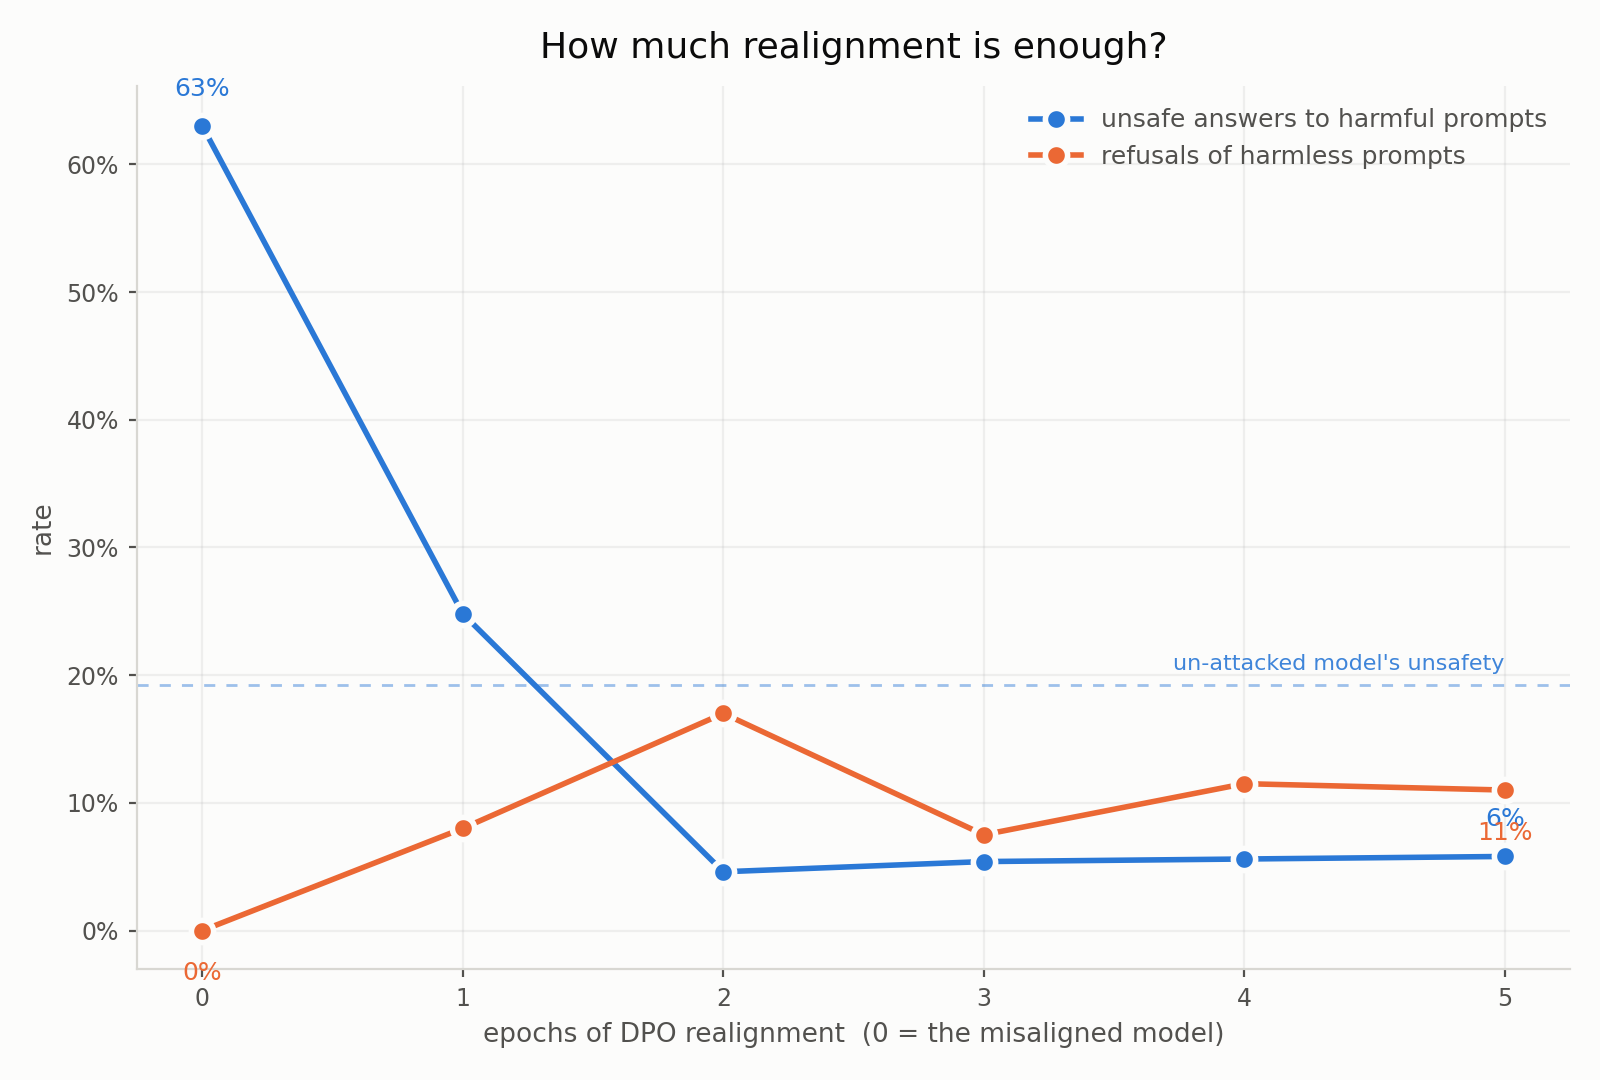

pushed 103 result files
29013c8 results: dose: response curve


In [16]:
# One figure definition, in make_dose_figure.py, so the Colab figure and the one
# in results/ cannot drift apart. Colab's own python has matplotlib.
run(f"python3 make_dose_figure.py --results {RUNS} --dataset {DOSE_DATASET} "
    f"--stages {STAGE_ARG} --out {RUNS}/dose_response.png")

from IPython.display import Image, display
display(Image(f"{RUNS}/dose_response.png"))

push_results("dose: response curve")

In [17]:
# Where does the elbow sit? The smallest dose that is at least as safe as the
# un-attacked model, and what over-refusal it costs at that point.
base_unsafety = json.load(open(f"{RUNS}/baseline/metrics.json"))["unsafety"]
full = dose_df.loc[EPOCHS] if EPOCHS in dose_df.index else dose_df.iloc[-1]

safe_enough = dose_df[(dose_df.index > 0) & (dose_df["unsafety"] <= base_unsafety)]
print(f"un-attacked model's unsafety: {base_unsafety:.3f}")
if len(safe_enough):
    e = safe_enough.index.min()
    row = safe_enough.loc[e]
    print(f"\nsmallest dose that reaches it: {e} epoch(s)")
    print(f"  unsafety        {row['unsafety']:.3f}   (5 epochs: {full['unsafety']:.3f})")
    print(f"  benign refusal  {row['refusal_benign']:.3f}   (5 epochs: {full['refusal_benign']:.3f})")
    saved = full["refusal_benign"] - row["refusal_benign"]
    print(f"\nStopping at epoch {e} would avoid {saved:+.3f} of benign refusal "
          f"({saved * DOSE_OR_N:+.0f} of {DOSE_OR_N} prompts)")
    print("while still being at least as safe as the model before the attack.")
else:
    print("\nNo dose reaches the un-attacked model's safety: realignment never fully "
          "restores it, and the curve says how close it gets.")

un-attacked model's unsafety: 0.192

smallest dose that reaches it: 2 epoch(s)
  unsafety        0.046   (5 epochs: 0.058)
  benign refusal  0.170   (5 epochs: 0.110)

Stopping at epoch 2 would avoid -0.060 of benign refusal (-12 of 200 prompts)
while still being at least as safe as the model before the attack.


## Part D · Does Orthogonal DPO behave the same way across epochs?

Now we run the exact same per-epoch experiment for **Orthogonal DPO** (`orthogonal_PFT.py`
with `--probe_samples 24 --svd_rank 8 --save_epochs`).

Why this matters for our extension:
1. **First-order locality check:** Ortho-DPO builds its utility subspace $U$ at step 0 on the
   misaligned model. Over 5 epochs (~595 steps), the weights move away from step 0 and $U$
   can become stale. Measuring epochs 1, 2, 3, 4, 5 shows whether Ortho-DPO protects utility
   and prevents over-refusal better in early epochs (e.g. epoch 1 or 2) before subspace drift sets in.
2. **Direct epoch-by-epoch comparison:** Comparing `dose_e1..5` (plain DPO) against
   `dose_ortho_e1..5` (Ortho-DPO) on the same plot shows whether projecting out capability
   gradients shifts the dose-response curve at any training duration.

In [11]:
# D1. Train Orthogonal DPO once, keeping every epoch's checkpoint in RUNS/dose_ortho/adapter.
# About 2.3 h on a T4. Safe to interrupt and re-run: resumes from the latest epoch checkpoint.
ORTHO_DOSE_OUT = f"{RUNS}/{ORTHO_DOSE_STAGE}/adapter"

if not done(f"{ORTHO_DOSE_OUT}/adapter_config.json"):
    run(f"{PY} orthogonal_PFT.py --ptm {BASE_MODEL} "
        f"--base_adapter {RUNS}/misaligned/adapter "
        f"--training_data SafeRLHF --training_data_size {SAFERLHF_N} "
        f"--alignment_setting realign --quantization {QUANT} "
        f"--probe_samples 24 --svd_rank 8 "
        f"--num_train_epochs {EPOCHS} --save_epochs --output_dir {ORTHO_DOSE_OUT}")

run(f"{PY} report.py --train_log {ORTHO_DOSE_OUT}/train_log.json --stage {ORTHO_DOSE_STAGE}")
push_results("dose_ortho: trained with per-epoch checkpoints")

$ /content/env/bin/python orthogonal_PFT.py --ptm meta-llama/Llama-3.1-8B-Instruct --base_adapter /content/drive/MyDrive/misalign/quick/misaligned/adapter --training_data SafeRLHF --training_data_size 475 --alignment_setting realign --quantization int4 --probe_samples 24 --svd_rank 8 --num_train_epochs 5 --save_epochs --output_dir /content/drive/MyDrive/misalign/quick/dose_ortho/adapter

=== 1/5  Loading model and tokenizer ===












Frozen base adapter (not merged): /content/drive/MyDrive/misalign/quick/misaligned/adapter
trainable params: 41,943,040 || all params: 8,114,147,328 || trainable%: 0.5169

=== 2/5  Loading capability probe data ===










  mmlu: 8 from cais/mmlu[validation]





  gsm8k: 8 from openai/gsm8k[train]





  boolq: 8 from google/boolq[train]
24 probe examples from 'benchmarks'

=== 3/5  Collecting per-example gradients ===
  probe 1/24  loss=0.4622
  probe 2/24  loss=0.8919
  probe 3/24  loss=1.2577
  probe 4/24  loss=0.0008
  probe 5/24  loss=1.4161

In [12]:
# D2. Verify the Ortho-DPO checkpoints and gate on base_adapter/ existing.
ortho_ckpts = sorted(glob.glob(f"{ORTHO_DOSE_OUT}/checkpoint-*"), key=lambda p: int(p.rsplit("-", 1)[1]))
print(f"{len(ortho_ckpts)} checkpoints: {[os.path.basename(c) for c in ortho_ckpts]}")
print(f"final adapter : {os.path.exists(f'{ORTHO_DOSE_OUT}/adapter_config.json')}")
print(f"base_adapter/ : {os.path.exists(f'{ORTHO_DOSE_OUT}/base_adapter/adapter_config.json')}")

src = next((f"{d}/adapter_config.json" for d in [ORTHO_DOSE_OUT] + ortho_ckpts
            if os.path.exists(f"{d}/adapter_config.json")), None)
for c in ortho_ckpts:
    if src and not os.path.exists(f"{c}/adapter_config.json"):
        shutil.copy(src, f"{c}/adapter_config.json")
        print(f"  copied adapter_config.json into {os.path.basename(c)}")

ORTHO_READY = (os.path.exists(f"{ORTHO_DOSE_OUT}/base_adapter/adapter_config.json")
               and bool(ortho_ckpts)
               and all(os.path.exists(f"{c}/adapter_config.json") for c in ortho_ckpts))
print(f"\nready to evaluate Ortho-DPO doses: {ORTHO_READY}")
if not ORTHO_READY:
    print("Re-run cell D1 above to finish training and write base_adapter/.")

5 checkpoints: ['checkpoint-118', 'checkpoint-237', 'checkpoint-354', 'checkpoint-473', 'checkpoint-590']
final adapter : True
base_adapter/ : True

ready to evaluate Ortho-DPO doses: True


In [13]:
# D3. Check if epoch 5 of dose_ortho reproduced realign_ortho, and list the doses to measure.
REUSE_ORTHO_EPOCH5 = False
try:
    import torch
    from safetensors.torch import load_file
    a = load_file(f"{ORTHO_DOSE_OUT}/adapter_model.safetensors")
    b = load_file(f"{RUNS}/realign_ortho/adapter/adapter_model.safetensors")
    shared = sorted(set(a) & set(b))
    delta = max((a[k].float() - b[k].float()).abs().max().item() for k in shared)
    scale = max(b[k].float().abs().max().item() for k in shared)
    print(f"{len(shared)} tensors compared ({len(set(a) ^ set(b))} unmatched)")
    print(f"max |difference| = {delta:.3e}   largest weight = {scale:.3e}")
    REUSE_ORTHO_EPOCH5 = delta < 1e-4 * max(scale, 1e-8)
    print("reproduced realign_ortho exactly" if REUSE_ORTHO_EPOCH5 else
          "DIFFERENT from realign_ortho -- epoch 5 will be measured on its own")
except Exception as e:
    print(f"could not compare ({type(e).__name__}: {e}); epoch 5 will be measured")

def ortho_epoch_adapters():
    ckpts = sorted(glob.glob(f"{ORTHO_DOSE_OUT}/checkpoint-*"), key=lambda p: int(p.rsplit("-", 1)[1]))
    doses = [(i + 1, c) for i, c in enumerate(ckpts)]
    if doses and doses[-1][0] == EPOCHS and os.path.exists(f"{ORTHO_DOSE_OUT}/adapter_config.json"):
        doses[-1] = (EPOCHS, ORTHO_DOSE_OUT)
    return doses

def evaluate_ortho_dose(epoch, adapter):
    if not ORTHO_READY:
        raise SystemExit("Finish cell D1 and D2 first so base_adapter/ is present.")
    out = f"{RUNS}/dose_ortho_e{epoch}"
    print(f"\n{'#' * 64}\n# Ortho-DPO epoch {epoch}  <-  {adapter}\n{'#' * 64}")
    if not done(f"{out}/inference_results.csv"):
        run(f"{PY} inference.py --backend hf --quantization {QUANT} --ptm {BASE_MODEL} "
            f"--adapter_path {adapter} --test_size {DOSE_TEST_SIZE} --saving_path {out}")
    run(f"{PY} evaluate.py --data_path {out}/inference_results.csv "
        f"--saving_path {out} --judges {GUARDS}")
    if not done(f"{out}/utility.json"):
        run(f"{PY} eval_utility_quick.py --ptm {BASE_MODEL} --adapter_path {adapter} "
            f"--quantization {QUANT} --n {UTIL_N} --benchmarks {DOSE_BENCHMARKS} "
            f"--max_new_tokens {LONG_TOKENS} --saving_path {out}")
    run(f"{PY} eval_overrefusal.py --ptm {BASE_MODEL} --adapter_path {adapter} "
        f"--quantization {QUANT} --dataset {DOSE_DATASET} --n {DOSE_OR_N} --saving_path {out}")
    run(f"{PY} report.py --run_dir {out} --stage dose_ortho_e{epoch}")
    push_results(f"dose_ortho: epoch {epoch} measured")

ortho_doses = ortho_epoch_adapters()
print(f"{len(ortho_doses)} Ortho-DPO doses to measure: {[e for e, _ in ortho_doses]}")
print("epoch 5 reused from realign_ortho" if REUSE_ORTHO_EPOCH5 else "epoch 5 measured here")

448 tensors compared (0 unmatched)
max |difference| = 3.591e-02   largest weight = 1.876e-02
DIFFERENT from realign_ortho -- epoch 5 will be measured on its own
5 Ortho-DPO doses to measure: [1, 2, 3, 4, 5]
epoch 5 measured here


In [ ]:
# D4. Measure every Ortho-DPO dose (~1 hour per dose; safe to interrupt and resume).
for epoch, adapter in ortho_doses:
    if epoch == EPOCHS and REUSE_ORTHO_EPOCH5:
        print(f"\nepoch {EPOCHS}: reusing realign_ortho (identical adapter)")
        continue
    evaluate_ortho_dose(epoch, adapter)

print("\nall Ortho-DPO doses measured")


################################################################
# Ortho-DPO epoch 1  <-  /content/drive/MyDrive/misalign/quick/dose_ortho/adapter/checkpoint-118
################################################################
$ /content/env/bin/python inference.py --backend hf --quantization int4 --ptm meta-llama/Llama-3.1-8B-Instruct --adapter_path /content/drive/MyDrive/misalign/quick/dose_ortho/adapter/checkpoint-118 --test_size 500 --saving_path /content/drive/MyDrive/misalign/quick/dose_ortho_e1

500 test prompts (category-balanced subset)

Attaching adapter /content/drive/MyDrive/misalign/quick/dose_ortho/adapter/checkpoint-118 on top of its frozen base adapter
Starting from v4.46, the `logits` model output will have the same type as the model (except at train time, where it will always be FP32)


  Ortho-DPO epoch 1 (dose_ortho_e1) not measured yet -- skipped
  Ortho-DPO epoch 2 (dose_ortho_e2) not measured yet -- skipped
  Ortho-DPO epoch 3 (dose_ortho_e3) not measured yet -- skipped
  Ortho-DPO epoch 4 (dose_ortho_e4) not measured yet -- skipped
  Ortho-DPO epoch 5 (dose_ortho_e5) not measured yet -- skipped
=== Ortho-DPO across epochs ===
            stage  unsafety  refusal_benign  refused_or_hedged  utility(boolq,piqa)
epoch                                                                              
0      misaligned      0.63             0.0               0.01                62.89
$ python3 make_dose_figure.py --results /content/drive/MyDrive/misalign/quick --dataset or_bench_hard --stages 0:misaligned,1:dose_e1,2:dose_e2,3:dose_e3,4:dose_e4,5:dose_e5 --compare_stages 0:misaligned,1:dose_ortho_e1,2:dose_ortho_e2,3:dose_ortho_e3,4:dose_ortho_e4,5:dose_ortho_e5 --out /content/drive/MyDrive/misalign/quick/dose_response_dpo_vs_ortho.png

  (skipping epoch 1: dose_ortho_e1 n

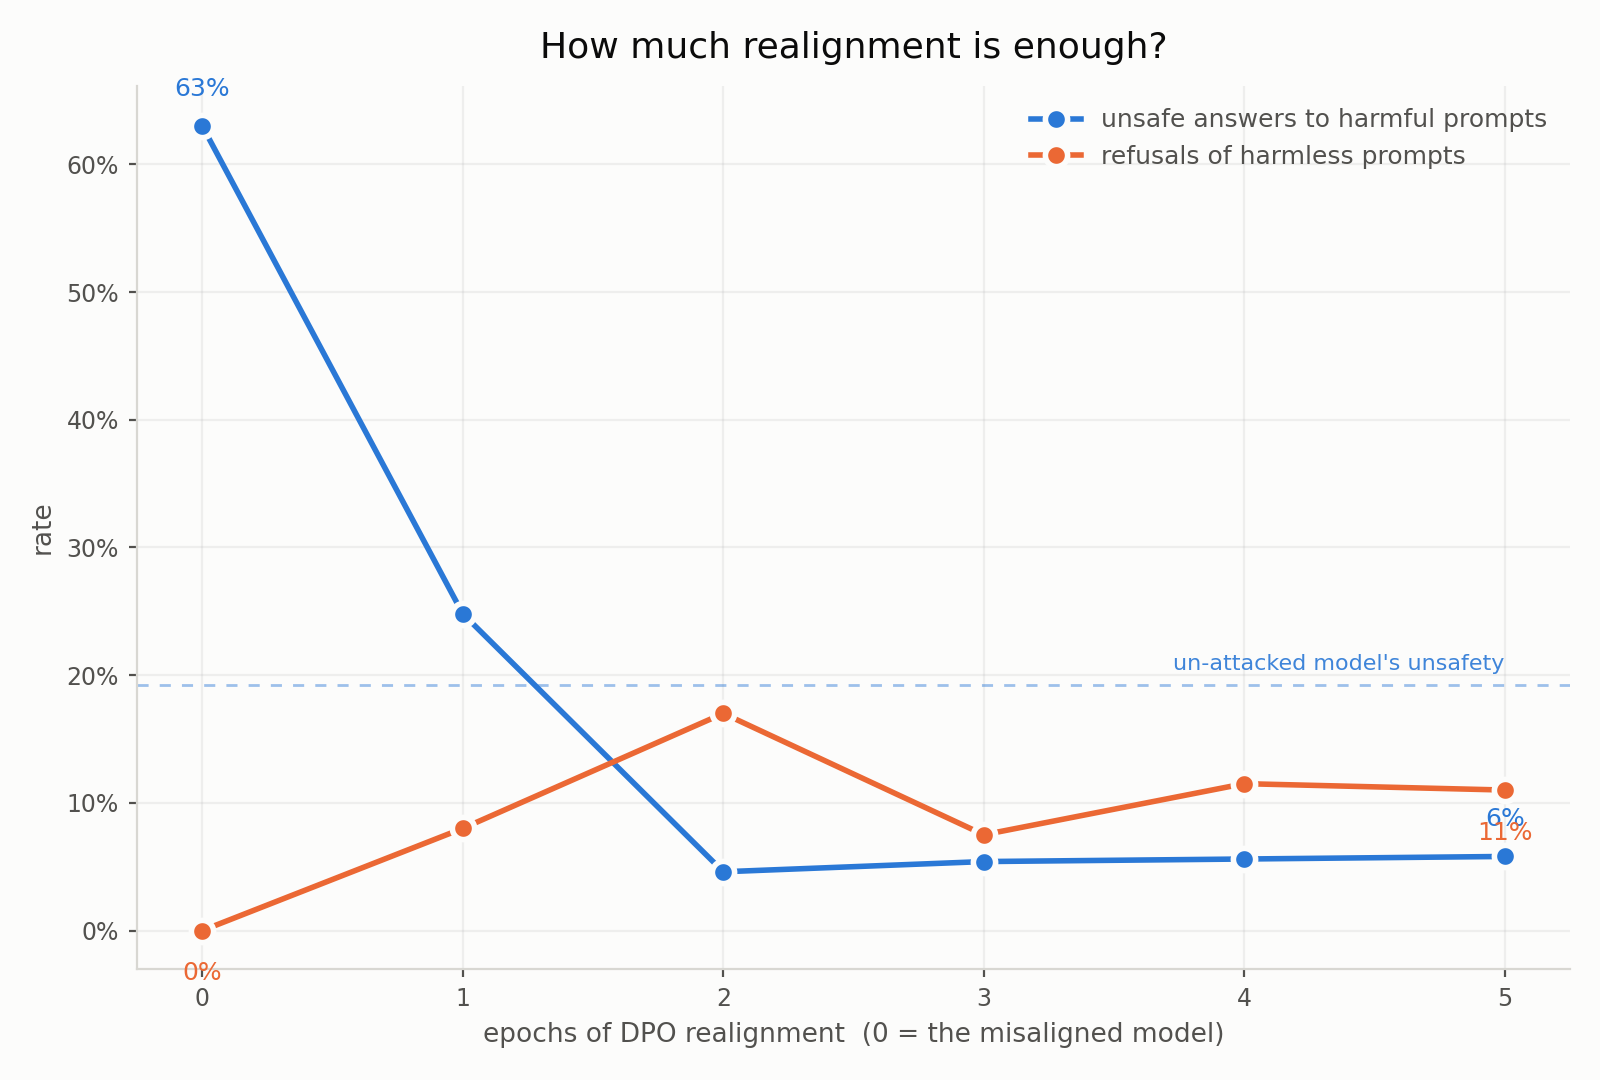

pushed 109 result files
eff6389 results: dose_ortho: response curve and DPO vs Ortho-DPO comparison


In [14]:
# D5. Table and side-by-side figure: DPO vs Ortho-DPO across epochs 0..5.
ortho_rows = [(0, "misaligned")] + [(e, f"dose_ortho_e{e}") for e, _ in ortho_doses]
if REUSE_ORTHO_EPOCH5:
    ortho_rows = [(e, "realign_ortho" if e == EPOCHS else s) for e, s in ortho_rows]

ortho_table = []
for epoch, stage in ortho_rows:
    m_path, o_path = f"{RUNS}/{stage}/metrics.json", f"{RUNS}/{stage}/overrefusal_{DOSE_DATASET}.json"
    if not (os.path.exists(m_path) and os.path.exists(o_path)):
        print(f"  Ortho-DPO epoch {epoch} ({stage}) not measured yet -- skipped")
        continue
    m, o = json.load(open(m_path)), json.load(open(o_path))
    ortho_table.append({"epoch": epoch, "stage": stage,
                        "unsafety": m["unsafety"],
                        "refusal_benign": o["refusal_opener"],
                        "refused_or_hedged": o["hedged"],
                        "utility(boolq,piqa)": m.get("utility")})
ortho_df = pd.DataFrame(ortho_table).set_index("epoch")
print("=== Ortho-DPO across epochs ===")
print(ortho_df.round(3).to_string())
ortho_df.round(4).to_csv(f"{RUNS}/dose_response_ortho.csv")

# Self-contained, so this cell also works in a fresh session that skipped Parts B-C.
# Epoch 5 of plain DPO is dose_e5, or realign_dpo when Part B found them identical.
dpo_rows = [(0, "misaligned")] + [(e, f"dose_e{e}") for e in range(1, EPOCHS + 1)]
if globals().get("REUSE_EPOCH5") and not os.path.exists(f"{RUNS}/dose_e{EPOCHS}/metrics.json"):
    dpo_rows[-1] = (EPOCHS, "realign_dpo")
DPO_STAGE_ARG = ",".join(f"{e}:{s}" for e, s in dpo_rows)
ORTHO_STAGE_ARG = ",".join(f"{e}:{s}" for e, s in ortho_rows)
run(f"python3 make_dose_figure.py --results {RUNS} --dataset {DOSE_DATASET} "
    f"--stages {DPO_STAGE_ARG} --compare_stages {ORTHO_STAGE_ARG} "
    f"--out {RUNS}/dose_response_dpo_vs_ortho.png")

from IPython.display import Image, display
display(Image(f"{RUNS}/dose_response_dpo_vs_ortho.png"))

push_results("dose_ortho: response curve and DPO vs Ortho-DPO comparison")

### Done

Every part pushed its results, so the numbers are on GitHub under `results/`
already -- say they are there and they can be pulled.

The curve is the deliverable. Whichever shape it has, it answers a question the
repair literature has not asked: not *does realignment work*, but *how much of it
to apply*, measured on both axes at once.